In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from pathlib import Path
import re
from typing import Optional, Union, Dict
from matplotlib.ticker import MultipleLocator
from scipy.interpolate import griddata
import matplotlib as mpl


In [2]:
class BFieldDataLoader:
    """
    Reads CSV files named like:
    {sample}_{experiment}_B_field_{field_used}_start_{start_frequency}.csv

    Combines files that share the same field_used into the same column,
    ordered by start_frequency.

    background_type can be "theoretical", "simulated", "results" or "results_ave"
    """

    FILE_PATTERN = re.compile(
        r"(?P<sample>.+?)_"
        r"(?P<experiment>.+?)_"
        r"B_field_"
        r"(?P<field_used>.+?)_"
        r"start_"
        r"(?P<start_frequency>[\d\.]+)\.csv$"
    )

    def __init__(self, data_path, background_path):
        self.data_path = Path(data_path)
        self.background_path = Path(background_path)

        if not self.data_path.exists():
            raise FileNotFoundError(f"Folder not found: {data_path}")
        if not self.background_path.exists():
            raise ValueError(f"Background path does not exist: {self.background_path}")
        
        self.data: Optional[pd.DataFrame] = self.load()
        self.background: Optional[pd.DataFrame] = None
        self.background_type: Optional[str] = None

        self.data_cleaned: Optional[pd.DataFrame] = None

        self.data_nV_sqrt_hz: Optional[pd.DataFrame] = None
        self.background_nV_sqrt_hz: Optional[pd.DataFrame] = None

        self.data_dbm_hz: Optional[pd.DataFrame] = None
        self.background_dbm_hz: Optional[pd.DataFrame] = None

    def linear_to_dbm(self, power_watts):
        power_dbm = 10 * np.log10(power_watts / 1e-3)
        return power_dbm

    def dbm_to_linear(self, power_dbm):
        power_watts = 1e-3 * (10 ** (power_dbm / 10))
        return power_watts    

    def _parse_filename(self, filename):
        match = self.FILE_PATTERN.match(filename)

        if not match:
            return None

        info = match.groupdict()
        info["start_frequency"] = float(info["start_frequency"])
        return info

    def load(self, folder_path = None):
        '''must call with the folder path containing the data files'''
        grouped_data = {}
        headers_used = ['Frequency (Hz)', 'Average Amplitude (dBm)', 'Amplitude Error']

        if folder_path is None:
            folder_path = self.data_path

        for file_path in folder_path.glob("*.csv"):
            parsed = self._parse_filename(file_path.name)

            if parsed is None:
                print(f"Skipping unmatched file: {file_path.name}")
                continue

            field_used = round(float(parsed["field_used"]), 3)
            start_frequency = parsed["start_frequency"]

            # Read the CSV
            df = pd.read_csv(file_path, comment='!', sep=',', names=headers_used, header=0)

            # Use frequency as the index and average amplitude as the values
            frequency = df["Frequency (Hz)"]
            amplitude = df["Average Amplitude (dBm)"]

            series = pd.Series(amplitude.values, index=frequency.values)
            series.index.name = "Frequency (Hz)"

            if field_used not in grouped_data:
                grouped_data[field_used] = []

            grouped_data[field_used].append((start_frequency, series))

        combined_columns = {}

        for field_used, series_list in grouped_data.items():
            # Sort by start frequency
            series_list.sort(key=lambda x: x[0])

            # Concatenate all series for the same field_used
            combined_series = pd.concat(
                [series for _, series in series_list]
            )

            # Remove duplicated frequencies if they appear
            combined_series = combined_series[~combined_series.index.duplicated(keep="first")]

            # Sort by frequency
            combined_series = combined_series.sort_index()

            combined_columns[field_used] = combined_series

        # Create final dataframe
        final_df = pd.DataFrame(combined_columns)
        final_df.index.name = "Frequency (Hz)"

        return final_df

    def load_background(self, background_type="results", **kwargs):
        '''There are three posible background types:
        theoretical - which is just the noise floor calculated from the system parameters
        simulated - which is a friss chain of the noise lost from the initial source temperature
        results - which is in the same format as sample data.
            results can be interpreted as individual subtraction for each field measurement or as averager across fields'''
        
        if not self.background_path.exists():
            raise ValueError(f"Background path does not exist: {self.background_path}")

        if background_type == "theoretical":
            self.background_type = "theoretical"

        elif background_type == "simulated":
            self.background_type = "simulated"

        elif "results" in background_type:

            background_df_db = self.load(self.background_path)

            if 'ave' in background_type:
                averaged_background_db = self.average_across_fields(background_df_db)
                self.background = averaged_background_db
                self.background_type = "results_ave"

            else:
                self.background = background_df_db
                self.background_type = "results"

        else:
            raise ValueError(f"Invalid background type: {background_type}")
        
        if "smooth" in kwargs and kwargs["smooth"]:
            if "window_size" in kwargs:
                window_size = kwargs["window_size"]
            else:
                window_size = 1001
            self.background = self.smooth_background(self.background, window_size=window_size)

        return self.background


    def subtract_background(self, smooth=False, window_size=1001):
        '''Subtracts the background from the data, aligning on frequency index'''
        if self.data is None:
            raise ValueError("Data not loaded")
        # if background_df is None:
        #     raise ValueError("Background not loaded")
        if self.background_type is None:
            raise ValueError("Background type not set. Call load_background() first.")


        if self.background_type in ["theoretical", "simulated"]:
            pass

        elif self.background_type in ["results", "results_ave"]:
            background_df = self.background.copy()

            if smooth:
                background_df = self.smooth_background(background_df, window_size=window_size)

            if 'ave' in self.background_type:
                corrected_data_db = self.data.copy()
                corrected_data = pd.DataFrame(index=corrected_data_db.index)
                background_df_linear = self.dbm_to_linear(background_df)
                background_offset = background_df_linear.mean()

                for col in corrected_data_db.columns:
                    data_col_linear = self.dbm_to_linear(corrected_data_db[col])

                    corrected_data[col] = data_col_linear.sub(background_df_linear)  
                    corrected_data[col] = corrected_data[col].add(background_offset)
                    # if results_ave is used, then the background df is already averaged from load background. so we can just subtract it from each column of the data after converting to linear power.
                
                corrected_data = self.linear_to_dbm(corrected_data)

            else:
            # Align on frequency index and subtract
                aligned_data, aligned_background = self.data.align(background_df, join="inner")

                corrected_data = aligned_data.subtract(aligned_background, axis=0)
                background_average = aligned_background.mean(axis=1, skipna=True)

                # add average background back
                corrected_data = corrected_data.add(background_average, axis=0)

            self.data_cleaned = corrected_data.copy()
            return corrected_data


    def average_across_fields(self, df):
        """
        Takes a dataframe with field values in dBm as columns and frequency
        as the index.

        Converts dBm to linear power, averages across all fields for each
        frequency, then converts back to dBm.
        """
        linear_power = self.dbm_to_linear(df)

        average_linear_power = linear_power.mean(axis=1, skipna=True)

        average_dbm = self.linear_to_dbm(average_linear_power)

        return average_dbm
    

    def smooth_background(self, background_series_db, window_size=101):
        """
        Applies a running average to a background series while preserving
        the same number of data points.

        Parameters
        ----------
        background_series : pd.Series
            Background amplitude values indexed by frequency.
        window_size : int
            Size of the moving average window. Should be an odd number.

        Returns
        -------
        pd.Series
            Smoothed background series with the same index length.
        """
        if window_size % 2 == 0:
            raise ValueError("window_size should be an odd number")
        
        linear_power = self.dbm_to_linear(background_series_db)

        smoothed = linear_power.rolling(
            window=window_size,
            center=True,
            min_periods=1
        ).mean()

        smoothed_dbm = self.linear_to_dbm(smoothed)

        return smoothed_dbm
    
    def dbm_to_dbm_hz(self, df, rbw_hz = 1e3, gain_db = 65):

        corrected_amplitude = df - gain_db
        psd_dbm_hz = corrected_amplitude - 10*np.log10(rbw_hz)

        return psd_dbm_hz


    def dbm_to_spectral_density(self, df, rbw_hz = 1e3, gain_db = 65, impedance=50):
        """
        Converts amplitude values from dBm to spectral density in nV/sqrt(Hz).

        Assumes the dBm values represent power in a 1 Hz bandwidth.

        Parameters
        ----------
        df : pd.DataFrame or pd.Series
            Input values in dBm.
        impedance : float
            System impedance in ohms.

        Returns
        -------
        pd.DataFrame or pd.Series
            Spectral density in nV/sqrt(Hz).
        """
        # Account for amplifiers
        corrected_dbm = df - gain_db

        # Convert dBm to power in watts
        power_watts = 1e-3 * (10 ** (corrected_dbm / 10))

        # Convert from total power in RBW to power spectral density
        power_density_watts = power_watts / rbw_hz

        # Convert power to voltage spectral density in V^2/Hz
        voltage_density = np.sqrt(power_density_watts * impedance)

        # Convert to nV^2/Hz
        voltage_density_nv_hz = voltage_density * 1e9

        return voltage_density_nv_hz
    
    # def calc_spectral_densities(self, psd_type):
    #     if self.data is None:
    #         raise ValueError("Data not loaded")
    #     if self.background is None:
    #         raise ValueError("Background not loaded")
    #     if psd_type.lower() not in ['power', 'amplitude']:
    #         raise ValueError("psd must be either power or amplitude")

    #     temp_df_bg = self.background.copy()
    #     temp_df_data = self.data.copy()

    #     if self.background_type == "results":
    #         if psd_type == 'amplitude':
    #             for i, col in enumerate(temp_df_bg.columns):
    #                 temp_df_bg[col] = self.dbm_to_spectral_density(self.background.iloc[:,i])
    #             for i, col in enumerate(temp_df_data.columns):
    #                 temp_df_data[col] = self.dbm_to_spectral_density(self.data.iloc[:,i])

    #             self.background_nV_sqrt_hz = temp_df_bg
    #             self.data_nV_sqrt_hz = temp_df_data

    #         elif psd_type == 'power':
    #             for i, col in enumerate(temp_df_bg.columns):
    #                 temp_df_bg[col] = self.dbm_to_dbm_hz(self.background.iloc[:,i])
    #             for i, col in enumerate(temp_df_data.columns):
    #                 temp_df_data[col] = self.dbm_to_dbm_hz(self.data.iloc[:,i])

    #             self.background_dbm_hz = temp_df_bg
    #             self.data_dbm_hz = temp_df_data

    #     elif self.background_type == "results_ave":
    #         if psd_type == 'amplitude':
    #             self.background_nV_sqrt_hz = self.dbm_to_spectral_density(self.background)
    #             for i, col in enumerate(temp_df_data.columns):
    #                 temp_df_data[col] = self.dbm_to_spectral_density(self.data.iloc[:,i])

    #             self.data_nV_sqrt_hz = temp_df_data
            
    #         elif psd_type == 'power':
    #             self.background_dbm_hz = self.dbm_to_dbm_hz(self.background)
    #             for i, col in enumerate(temp_df_data.columns):
    #                 temp_df_data[col] = self.dbm_to_dbm_hz(self.data.iloc[:,i])

    #             self.data_dbm_hz = temp_df_data


    #     return temp_df_bg, temp_df_data

    
    def plot_colormap(self, spectral_density_df, interpolate=True, cmap="viridis", vmin=None, vmax=None, ax=None, add_colorbar=True, kittel=None, save_path: Optional[str] = None, dpi: int = 300, **kwargs):
        """
        Plots a colormap with:
        - x-axis: frequency
        - y-axis: field
        - color: spectral density

        Parameters
        ----------
        spectral_density_df : pd.DataFrame
            Dataframe indexed by frequency with field values as columns.
        interpolate : bool
            If True, interpolate NaN values before plotting.
        cmap : str
            Matplotlib colormap name.
        """

        plot_df = spectral_density_df.copy()

        frequencies = plot_df.index.values.astype(float)
        fields = np.array([float(i) for i in plot_df.columns])

      
        if interpolate:

            # convert to numpy
            Z = plot_df.T.values.astype(float)

            # fast NaN filling
            # mask = np.isnan(Z)

            # fill NaNs with nearest non-NaN values along rows/cols
            filled = pd.DataFrame(Z).ffill(axis=0).bfill(axis=0)
            filled = filled.ffill(axis=1).bfill(axis=1)

            Z = filled.values

        else:
            Z = plot_df.T.values
            

        if kittel is not None:
            kittel_data = kittel[(kittel['B(T)'] >= min(fields)) & (kittel['B(T)'] <= max(fields))].copy()

            kittel_series = pd.Series(kittel_data['B(T)'].values, index=kittel_data['freq(Hz)'])
            kittel_series.name = "Kittel Fit"

        X, Y = np.meshgrid(frequencies, fields)
        # Z = plot_df.T.values
        
        if ax is None:
            fig, ax = plt.subplots(figsize=(10, 6))

            ax.set_xlim(X.min()/1e9, X.max()/1e9)


            ax.legend(fontsize = 12, loc="upper right")
            
            # ml = MultipleLocator(2)
            # m2 = MultipleLocator(0.5)

            # ax.yaxis.set_major_locator(ml)
            # ax.yaxis.set_minor_locator(m2)
            ax.set_ylabel("Magnetic Field (mT)", fontsize = 14)
            ax.set_xlabel("Frequency (GHz)", fontsize = 14)

        else:
            fig = ax.figure

        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)

        if (vmax is None) and (Z.min()>0):
            vmax = min(Z.max(), 6)

        mesh = ax.pcolormesh(
            X/1e9,
            Y*1e3,
            Z,
            shading="auto",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            rasterized=True
        )

        if kittel is not None:
            ax.plot(kittel_series.index/1e9, kittel_series.values*1e3, label="Kittel Fit", color="red", ls="--")
        # print(kittel_series)
        
        ax.set_ylim(Y.min()*1e3, Y.max()*1e3)

        # cbar = fig.colorbar(mesh)

        if 'cm_label' in kwargs:
            bar_label = kwargs['cm_label']
        else:
            bar_label = "Spectral Density"

        if add_colorbar:
            cbar = fig.colorbar(mesh, ax=ax)
            cbar.set_label(f'{bar_label}', fontsize=14)

     

        if save_path is not None:
            save_path = Path(save_path)

            try:
                save_path.parent.mkdir(parents=True, exist_ok=True)
            except Exception as e:
                print(f"Error creating directories for {save_path.parent}: {e}")
                return

            fig.savefig(
                save_path,
                format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
                dpi=dpi,
                bbox_inches="tight"
            )

        return mesh

    def run_analysis(self, sample, sd_type, **kwargs):
        if 'bg_type' in kwargs:
            self.load_background(background_type=kwargs['bg_type'])
        else:
            self.load_background(background_type="results")
        
        # self.calc_spectral_densities(psd_type=sd_type)##

        if 'smooth' in kwargs:
            smooth_bg = kwargs['smooth']
        else:
            smooth_bg = False

        df_psd = self.data.copy()

        cols = df_psd.columns
        fields = [float(i) for i in cols]

        if sample.lower() == 'py':

            gamma = 30.69e9  # gyromagnetic ratio in Hz/T
            M_sat = 605e3  # saturation magnetization in A/m

        elif sample.lower() == 'yig':

            gamma = 26.98e9  # gyromagnetic ratio in Hz/T
            M_sat = 198e3  # saturation magnetization in A/m

        kittel_regression = pd.DataFrame()
        kittel_regression['B(T)'] = fields
        kittel_regression['freq(Hz)'] = [gamma*np.sqrt(i*(i+1.2566e-6*M_sat)) for i in fields]

        if 'f_min' in kwargs:
            f_min = kwargs['f_min']
        else:
            f_min = df_psd.index.min()

        if 'f_max' in kwargs:
            f_max = kwargs['f_max']
        else:
            f_max = df_psd.index.max()

        if 'no_bg' in kwargs:
            df_colormap_temp = df_psd
            df_colormap = df_colormap_temp.loc[f_min:f_max].copy()

        else:
            df_colormap_temp = self.subtract_background(smooth=smooth_bg, window_size=1001)
            df_colormap = df_colormap_temp.loc[f_min:f_max].copy()

            # df_colormap = self.dbm_to_dbm_hz(df_colormap)

        if sd_type == 'power':
            df_colormap = self.dbm_to_dbm_hz(df_colormap)
            colormap_label = "Power Spectral Density (dBm/Hz)"

        elif sd_type == 'amplitude':
            df_colormap = self.dbm_to_spectral_density(df_colormap)
            colormap_label = "Spectral Density (nV/$\sqrt{{Hz}}$)"
        
        else:
            raise ValueError("sd_type is not amplitude or power")
        

        if 'save_path' in kwargs:
            save_path = kwargs['save_path']
            self.plot_colormap(df_colormap, kittel=kittel_regression, cm_label = colormap_label, save_path=save_path)

        elif 'no_plot' in kwargs:
            return df_colormap, kittel_regression
        
        else:
            self.plot_colormap(df_colormap, kittel=kittel_regression, cm_label=colormap_label, **kwargs)


        


In [3]:
FOLDER_PATH = 'C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\Masters Project\\Results\\Experiments\\Spectrum_analyser_iMNS\\Results\\14-04-2026\\'
SAVE_FOLDER = 'C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\Masters Project\\Results\\Experiments\\Spectrum_analyser_iMNS\\Plots\\'

In [4]:
# the data i decided to use for my final plots.
py_hot_rt = BFieldDataLoader(f'{FOLDER_PATH}14-29-24', f'{FOLDER_PATH}14-51-13')
Py_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}14-51-13')
py_rt_rt = BFieldDataLoader(f'{FOLDER_PATH}14-51-13', f'{FOLDER_PATH}14-51-13')
# yig_hot_rt_nosamp = BFieldDataLoader(f'{FOLDER_PATH}13-20-19', f'{FOLDER_PATH}10-56-57-nosample')
# yig_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}16-23-33', f'{FOLDER_PATH}11-58-14')

# Py_ln2_ln2_nosamp = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}15-41-06-py-nosample')



In [ ]:

df1, kittel1 = Py_ln2_rt.run_analysis(sample='py', sd_type='amplitude', bg_type='results', smooth=True, window_size=10001, no_plot=True, no_bg=True)
# df2 = Py_ln2_rt.dbm_to_spectral_density(Py_ln2_rt.background)
df2, kittel2 = py_rt_rt.run_analysis(sample='py', sd_type='amplitude', bg_type='results', smooth=True, window_size=10001, no_plot=True, no_bg=True )
df3, kittel3 = py_hot_rt.run_analysis(sample='py', sd_type='amplitude', bg_type='results', smooth=True, window_size=10001, no_plot=True, no_bg=True)


In [5]:
plt.rcParams.update({
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})

In [ ]:
fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(16,4),
    sharey=True,
)
fig.subplots_adjust(wspace=0.15)

mesh1 = Py_ln2_rt.plot_colormap(df1, kittel=kittel1 ,ax=ax[0], add_colorbar=False, vmax=2)
mesh2 = py_rt_rt.plot_colormap(df2, kittel=kittel2, ax=ax[1], add_colorbar=False, vmax=2)
mesh3 = py_hot_rt.plot_colormap(df3, kittel=kittel3, ax=ax[2], add_colorbar=False, vmax=2)


fig.colorbar(mesh3, ax=ax.ravel().tolist(), pad=0.02, location="right",).set_label("Spectral Density (nV/$\sqrt{{Hz}}$)", fontsize=14)


ax[0].set_title("T = 77K", fontsize=14)
ax[1].set_title("T = 290K", fontsize=14)
ax[2].set_title("T = 9600K", fontsize=14)

ax[0].set_ylabel("Magnetic Field (mT)", fontsize=14)
ax[1].set_xlabel("Frequency (GHz)", fontsize=14)


ml = MultipleLocator(0.15)
m2 = MultipleLocator(0.025)


for a in ax:
    a.set_xlim(6.85, 7.15)
    a.set_xticks(np.arange(6.85, 7.15 + 0.001, 0.15))
    a.xaxis.set_minor_locator(m2)

# plt.xticks(fontsize=12)
# plt.yticks(fontsize=12)

# plt.tight_layout()
plt.show()

save_path = Path(f'{SAVE_FOLDER}\\iMNS_colormaps_py.svg')

fig.savefig(
    save_path,
    format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
    dpi=300,
    bbox_inches="tight"
    )

In [6]:
yig_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}16-23-33', f'{FOLDER_PATH}11-58-14')
yig_rt_rt = BFieldDataLoader(f'{FOLDER_PATH}11-58-14', f'{FOLDER_PATH}11-58-14')
yig_hot_rt = BFieldDataLoader(f'{FOLDER_PATH}13-20-19', f'{FOLDER_PATH}11-58-14')
# yig_hot_rt2 = BFieldDataLoader(f'{FOLDER_PATH}12-34-17', f'{FOLDER_PATH}11-58-14')

In [ ]:

df4, kittel4 = yig_ln2_rt.run_analysis(sample='yig', sd_type='amplitude', bg_type='results', smooth=True, window_size=10001, no_plot=True, no_bg=True)
# df2 = Py_ln2_rt.dbm_to_spectral_density(Py_ln2_rt.background)
df5, kittel5 = yig_rt_rt.run_analysis(sample='yig', sd_type='amplitude', bg_type='results', smooth=True, window_size=10001, no_plot=True, no_bg=True )
df6, kittel6 = yig_hot_rt.run_analysis(sample='yig', sd_type='amplitude', bg_type='results', smooth=True, window_size=10001, no_plot=True, no_bg=True)

In [ ]:
fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(16,4),
    sharey=True,
)
fig.subplots_adjust(wspace=0.15)

mesh1 = yig_ln2_rt.plot_colormap(df4, kittel=kittel4, ax=ax[0], add_colorbar=False, vmax=2)
mesh2 = yig_rt_rt.plot_colormap(df5, kittel=kittel5, ax=ax[1], add_colorbar=False, vmax=2)
mesh3 = yig_hot_rt.plot_colormap(df6, kittel=kittel6, ax=ax[2], add_colorbar=False, vmax=2)


fig.colorbar(mesh3, ax=ax.ravel().tolist(), pad=0.02, location="right",).set_label("Spectral Density (nV/$\sqrt{{Hz}}$)", fontsize=14)


ax[0].set_title("T = 77K", fontsize=14)
ax[1].set_title("T = 290K", fontsize=14)
ax[2].set_title("T = 9600K", fontsize=14)

ax[0].set_ylabel("Magnetic Field (mT)", fontsize=14)
ax[1].set_xlabel("Frequency (GHz)", fontsize=14)


ml = MultipleLocator(0.15)
m2 = MultipleLocator(0.025)


for a in ax:
    a.set_xlim(6.85, 7.15)
    a.set_xticks(np.arange(6.85, 7.15 + 0.001, 0.15))
    a.xaxis.set_minor_locator(m2)

# plt.xticks(fontsize=12)
# plt.yticks(fontsize=12)

# plt.tight_layout()
plt.show()

save_path = Path(f'{SAVE_FOLDER}\\iMNS_colormaps_yig.svg')

# fig.savefig(
#     save_path,
#     format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
#     dpi=300,
#     bbox_inches="tight"
#     )

In [ ]:
# T_source = 9600 #K
# T_source = 77
# T_source = 290

def friis_chain(T_source=77):
    S21_ave = -0.03 #db
    G_att = 10**(S21_ave/10) #linear

    G1_db = 22 #db
    G1 = 10**(G1_db/10) #linear
    F1 = 1.4 #db

    G2_db = 22 #db
    G2 = 10**(G2_db/10) #linear
    F2 = 1.4 #db

    G3_db = 21 #db
    G3 = 10**(G3_db/10) #linear
    F3 = 1.6 #db

    T_ref = 290 #K

    F = 10**(F1/10) + (10**(F2/10)-1)/G1 + (10**(F3/10)-1)/(G1*G2)
    T_e = (F-1)*T_ref

    T_att = (T_source*G_att + T_ref*(1-G_att))

    # T_sys = T_att + (10**(F1/10)-1)*T_ref + ((10**(F2/10)-1)*T_ref)/G1 + ((10**(F3/10)-1)*T_ref)/(G1*G2)

    # T_out = T_sys * G1 * G2 * G3 * G_att

    T_out = T_att + T_e

    return T_out


In [ ]:
fig, axes = plt.subplots(2,3, figsize=(12, 6), sharex=True, sharey='row')

def thermal_noise_voltage_density(temperature_k=290, impedance_ohms=50, friis=True):
    k_B = 1.380649e-23  # Boltzmann constant in J/K
    if friis:
        T = friis_chain(temperature_k)  # System noise temperature in Kelvin
    else:
        T = temperature_k  # Temperature in Kelvin
    R = impedance_ohms  # Resistance in ohms

    # Calculate the thermal noise voltage density in V/sqrt(Hz)
    voltage_density_v_hz = np.sqrt(k_B * T * R)

    # Convert to nV/sqrt(Hz)
    voltage_density_nv_hz = voltage_density_v_hz * 1e9

    return voltage_density_nv_hz


# rows for dbm and psd, columns for cold, rt, and hot data

num = 1

cmap = mpl.colormaps['viridis']

c = 'skyblue'


norm = mpl.colors.Normalize(
    vmin=0,
    vmax=2
)

# dotted lines:

# # bottom left
# bl_c_friis = thermal_noise_voltage_density(temperature_k=77)
# bl_c = thermal_noise_voltage_density(temperature_k=77, friis=False)

# c_bl1 = cmap(norm(bl_c_friis))
# c_bl2 = cmap(norm(bl_c))

# #bottom middle (rt)

# bm_c_friis = thermal_noise_voltage_density(temperature_k=290)

# c_bm = cmap(norm(bm_c_friis))


# #bottom right

# br_c_friis = thermal_noise_voltage_density(temperature_k=9600)
# br_c = thermal_noise_voltage_density(temperature_k=9600, friis=False)

# c_br = cmap(norm(br_c_friis))
# c_br2 = cmap(norm(br_c))



#hard set colors

c_bl1 = 'cyan'
c_bl2 = 'blue'

c_bm = 'yellow'

c_br = 'orange'
c_br2 = 'red'

#top left
cold_dbm = Py_ln2_rt.data
axes[0,0].plot(cold_dbm.index.values/1e9, cold_dbm.iloc[:,num].values-65, color=c ,  label=f'Py Data at {cold_dbm.columns[num]*1e3} mT')

#top middle
rt_dbm = py_rt_rt.data
axes[0,1].plot(rt_dbm.index.values/1e9, rt_dbm.iloc[:,num].values-65, color=c, label=f'Py Data at {rt_dbm.columns[num]*1e3} mT')


#top right
hot_dbm = py_hot_rt.data
axes[0,2].plot(hot_dbm.index.values/1e9, hot_dbm.iloc[:,num].values-65, color=c, label=f'Py Data at {hot_dbm.columns[num]*1e3} mT')


#bottom left
psd_cold = Py_ln2_rt.dbm_to_spectral_density(Py_ln2_rt.data)

axes[1,0].plot(psd_cold.index.values/1e9, psd_cold.iloc[:,num].values, color=c)
axes[1,0].hlines(thermal_noise_voltage_density(temperature_k=77), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_bl1, linestyles='--', label="Friis 77K")
axes[1,0].hlines(thermal_noise_voltage_density(temperature_k=77, friis=False), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_bl2, linestyles='--', label="77K")


#bottom middle
psd_rt = py_rt_rt.dbm_to_spectral_density(py_rt_rt.data)
axes[1,1].plot(psd_rt.index.values/1e9, psd_rt.iloc[:,num].values, color=c)
# axes[1,0].hlines(thermal_noise_voltage_density(temperature_k=290), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors='gray', linestyles='--', label="RT nV/$\sqrt{Hz}$")


#bottom right
psd_hot = py_hot_rt.dbm_to_spectral_density(py_hot_rt.data)
axes[1,2].plot(psd_hot.index.values/1e9, psd_hot.iloc[:,num].values, color=c)
axes[1,2].hlines(thermal_noise_voltage_density(temperature_k=9600), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_br, linestyles='--', label="Friis 9600K")
axes[1,2].hlines(thermal_noise_voltage_density(temperature_k=9600, friis=False), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_br2, linestyles='--', label="9600K")




for i in range(3):
    axes[0,i].set_ylim(-160, -100)
    axes[1,i].set_ylim(0, 2.75)
    axes[1,i].hlines(thermal_noise_voltage_density(), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_bm, linestyles='--', label="290 K")


    # axes[1,i].legend(fontsize=10, loc="upper right")

axes[0,0].set_title("T = 77K", fontsize=14)
axes[0,1].set_title("T = 290K", fontsize=14)
axes[0,2].set_title("T = 9600K", fontsize=14)

axes[0,0].set_ylabel("Amplitude (dBm)", fontsize=14)
axes[1,0].set_ylabel("Spectral Density (nV/$\sqrt{{Hz}}$)", fontsize=14)

axes[1,1].set_xlabel("Frequency (GHz)", fontsize=14)


fig.subplots_adjust(wspace=0.15)


handles = []
labels = []

for a in axes.flat:
    h, l = a.get_legend_handles_labels()

    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.035),
    ncol=len(labels),
    frameon=False,
    fontsize=12
)

fig.align_ylabels(axes[:,:])



save_path = Path(f'{SAVE_FOLDER}\\dbm_psd_analysis_py.svg')

fig.savefig(
    save_path,
    format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
    dpi=300,
    bbox_inches="tight"
    )

In [ ]:
fig, axes = plt.subplots(2,3, figsize=(12, 6), sharex=True, sharey='row')

def thermal_noise_voltage_density(temperature_k=290, impedance_ohms=50, friis=True):
    k_B = 1.380649e-23  # Boltzmann constant in J/K
    if friis:
        T = friis_chain(temperature_k)  # System noise temperature in Kelvin
    else:
        T = temperature_k  # Temperature in Kelvin
    R = impedance_ohms  # Resistance in ohms

    # Calculate the thermal noise voltage density in V/sqrt(Hz)
    voltage_density_v_hz = np.sqrt(k_B * T * R)

    # Convert to nV/sqrt(Hz)
    voltage_density_nv_hz = voltage_density_v_hz * 1e9

    return voltage_density_nv_hz


# rows for dbm and psd, columns for cold, rt, and hot data

num = 0

cmap = mpl.colormaps['viridis']

c = 'skyblue'


norm = mpl.colors.Normalize(
    vmin=0,
    vmax=2
)

# dotted lines:

# # bottom left
# bl_c_friis = thermal_noise_voltage_density(temperature_k=77)
# bl_c = thermal_noise_voltage_density(temperature_k=77, friis=False)

# c_bl1 = cmap(norm(bl_c_friis))
# c_bl2 = cmap(norm(bl_c))

# #bottom middle (rt)

# bm_c_friis = thermal_noise_voltage_density(temperature_k=290)

# c_bm = cmap(norm(bm_c_friis))


# #bottom right

# br_c_friis = thermal_noise_voltage_density(temperature_k=9600)
# br_c = thermal_noise_voltage_density(temperature_k=9600, friis=False)

# c_br = cmap(norm(br_c_friis))
# c_br2 = cmap(norm(br_c))



#hard set colors

c_bl1 = 'cyan'
c_bl2 = 'blue'

c_bm = 'yellow'

c_br = 'orange'
c_br2 = 'red'

#top left
cold_dbm = yig_ln2_rt.data
axes[0,0].plot(cold_dbm.index.values/1e9, cold_dbm.iloc[:,num].values-65, color=c ,  label=f'YIG Data at {cold_dbm.columns[num]*1e3} mT')

#top middle
rt_dbm = yig_rt_rt.data
axes[0,1].plot(rt_dbm.index.values/1e9, rt_dbm.iloc[:,num].values-65, color=c, label=f'YIG Data at {rt_dbm.columns[num]*1e3} mT')


#top right
hot_dbm = yig_hot_rt.data
axes[0,2].plot(hot_dbm.index.values/1e9, hot_dbm.iloc[:,num].values-65, color=c, label=f'YIG Data at {hot_dbm.columns[num]*1e3} mT')


#bottom left
psd_cold = yig_ln2_rt.dbm_to_spectral_density(yig_ln2_rt.data)

axes[1,0].plot(psd_cold.index.values/1e9, psd_cold.iloc[:,num].values, color=c)
axes[1,0].hlines(thermal_noise_voltage_density(temperature_k=77), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_bl1, linestyles='--', label="Friis 77K")
axes[1,0].hlines(thermal_noise_voltage_density(temperature_k=77, friis=False), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_bl2, linestyles='--', label="77K")


#bottom middle
psd_rt = yig_rt_rt.dbm_to_spectral_density(yig_rt_rt.data)
axes[1,1].plot(psd_rt.index.values/1e9, psd_rt.iloc[:,num].values, color=c)
# axes[1,0].hlines(thermal_noise_voltage_density(temperature_k=290), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors='gray', linestyles='--', label="RT nV/$\sqrt{Hz}$")


#bottom right
psd_hot = yig_hot_rt.dbm_to_spectral_density(yig_hot_rt.data)
axes[1,2].plot(psd_hot.index.values/1e9, psd_hot.iloc[:,num].values, color=c)
axes[1,2].hlines(thermal_noise_voltage_density(temperature_k=9600), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_br, linestyles='--', label="Friis 9600K")
axes[1,2].hlines(thermal_noise_voltage_density(temperature_k=9600, friis=False), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_br2, linestyles='--', label="9600K")




for i in range(3):
    axes[0,i].set_ylim(-160, -100)
    axes[1,i].set_ylim(0, 2.75)
    axes[1,i].hlines(thermal_noise_voltage_density(), psd_cold.index.min()/1e9, psd_cold.index.max()/1e9, colors=c_bm, linestyles='--', label="290 K")


    # axes[1,i].legend(fontsize=10, loc="upper right")

axes[0,0].set_title("T = 77K", fontsize=14)
axes[0,1].set_title("T = 290K", fontsize=14)
axes[0,2].set_title("T = 9600K", fontsize=14)

axes[0,0].set_ylabel("Amplitude (dBm)", fontsize=14)
axes[1,0].set_ylabel("Spectral Density (nV/$\sqrt{{Hz}}$)", fontsize=14)

axes[1,1].set_xlabel("Frequency (GHz)", fontsize=14)


fig.subplots_adjust(wspace=0.15)


handles = []
labels = []

for a in axes.flat:
    h, l = a.get_legend_handles_labels()

    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.035),
    ncol=len(labels),
    frameon=False,
    fontsize=12
)

fig.align_ylabels(axes[:,:])



save_path = Path(f'{SAVE_FOLDER}\\dbm_psd_analysis_yig.svg')

fig.savefig(
    save_path,
    format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
    dpi=300,
    bbox_inches="tight"
    )

In [ ]:

data_py = py_rt_rt.data.copy()
data_yig = yig_rt_rt.data.copy()


In [ ]:
fig, axes = plt.subplots(1,2, figsize=(11,4), sharey=True)


for column in data_py.columns:
    series = data_py[column]
    axes[0].plot(series.index/1e9, series.values-65, alpha=0.2)


for column in data_yig.columns:
    series = data_yig[column]
    axes[1].plot(series.index/1e9, series.values-65, alpha=0.2)

for ax in axes:
    ax.vlines(x=[np.linspace(6.85,7.151,7)], ymin=-160, ymax=-110, ls='--', color = 'k')

axes[0].set_ylabel("Amplitude (dBm)", fontsize=14)
fig.supxlabel("Frequency (GHz)", fontsize=14, y=-0.05)

fig.subplots_adjust(wspace=0.1)


axes[0].set_title("Py", fontsize=14)
axes[1].set_title("YIG", fontsize=14)

# save_path = Path(f'{SAVE_FOLDER}\\SA_spacing.svg')

# fig.savefig(
#     save_path,
#     format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
#     dpi=300,
#     bbox_inches="tight"
#     )



In [ ]:
# py_rt_rt.load_background(background_type="results")

background_df = py_rt_rt.background.copy()

background_ave = py_rt_rt.average_across_fields(background_df)

background_smoothed_lot = py_rt_rt.smooth_background(background_df, window_size=10001)

background_smoothed_little = py_rt_rt.smooth_background(background_df, window_size=101)





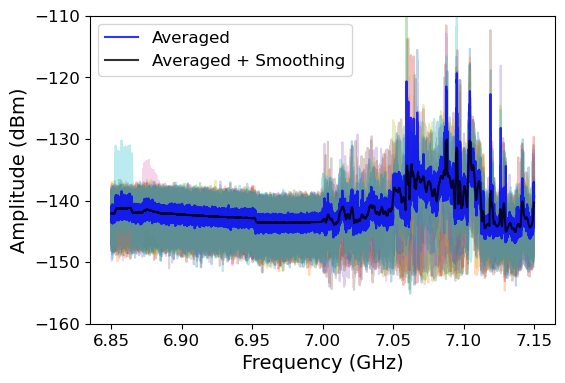

In [37]:
fig, ax = plt.subplots(figsize=(6,4))

# print(background_smoothed.shape)
bg_ave_smooth = py_rt_rt.smooth_background(background_ave, window_size=5001)


for i, col in enumerate(background_df.columns):
    ax.plot(background_df.index/1e9, background_df.iloc[:,i].values-65, alpha=0.3)

ax.plot(background_ave.index/1e9, background_ave.values-65, label="Averaged", color='blue', alpha=0.8)
ax.plot(bg_ave_smooth.index/1e9, bg_ave_smooth.values-65, label="Averaged + Smoothing", color='black', alpha=0.8)

# ax.plot(background_smoothed_little.index/1e9, background_smoothed_little.iloc[:,0].values, label="Smoothed Background", color='green', alpha=0.8)
# ax.plot(background_smoothed_lot.index/1e9, background_smoothed_lot.iloc[:,0].values, label="Smoothed Background", color='red', alpha=0.8)

ax.set_xlabel("Frequency (GHz)", fontsize=14)

ax.set_ylabel("Amplitude (dBm)", fontsize=14)

ax.legend(fontsize = 12, loc="upper left")

ax.set_ylim(-160, -110)


save_path = Path(f'{SAVE_FOLDER}\\bg_averaging.svg')

fig.savefig(
    save_path,
    format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
    dpi=300,
    bbox_inches="tight"
    )

#smoothing used here = 5001

59.0


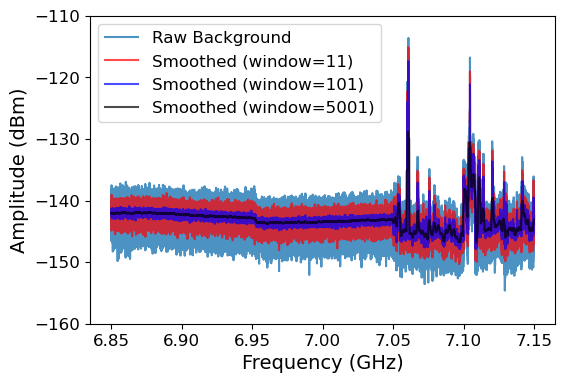

In [44]:
fig, ax = plt.subplots(figsize=(6,4))

num = 1

print(py_rt_rt.background.columns[num]*1e3)

window_sizes = [11, 101, 5001]
bg_smooth_1 = py_rt_rt.smooth_background(background_df, window_size=window_sizes[0])
bg_smooth_2 = py_rt_rt.smooth_background(background_df, window_size=window_sizes[1])
bg_smooth_3 = py_rt_rt.smooth_background(background_df, window_size=window_sizes[2])


ax.plot(background_df.index/1e9, background_df.iloc[:,num].values-65, alpha=0.8, label="Raw Background")

for window_size, bg_smooth, c in zip(window_sizes, [bg_smooth_1, bg_smooth_2, bg_smooth_3], ['red', 'blue', 'black']):
    ax.plot(bg_smooth.index/1e9, bg_smooth.iloc[:,num].values-65, label=f"Smoothed (window={window_size})", alpha=0.7, color=c)



ax.set_xlabel("Frequency (GHz)", fontsize=14)

ax.set_ylabel("Amplitude (dBm)", fontsize=14)

ax.set_ylim(-160, -110)

ax.legend(fontsize=12, loc="upper left")


save_path = Path(f'{SAVE_FOLDER}\\bg_smoothing.svg')

# fig.savefig(
#     save_path,
#     format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
#     dpi=300,
#     bbox_inches="tight"
#     )


In [ ]:
#permalloy different backgrounds data (cold)

# ln2 no sample 
Py_ln2_ln2_nosamp = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}15-41-06-py-nosample')

#rt sample
Py_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}14-51-13')

#rt no sample




In [ ]:
Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'amplitude', no_bg=True)

Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results')
Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results', smooth = True)


Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results_ave')
Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results_ave', smooth = True)





In [ ]:
Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'power', no_bg=True)

Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'power', bg_type='results', interpolate=False)
Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'power', bg_type='results', smooth = True,interpolate=False)


Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'power', bg_type='results_ave',interpolate=False)
Py_ln2_ln2_nosamp.run_analysis(sample='py', sd_type = 'power', bg_type='results_ave', smooth = True,interpolate=False)



In [ ]:
Py_ln2_rt.run_analysis(sample='py', sd_type = 'amplitude', no_bg=True)

Py_ln2_rt.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results')
Py_ln2_rt.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results', smooth = True)


Py_ln2_rt.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results_ave')
Py_ln2_rt.run_analysis(sample='py', sd_type = 'amplitude', bg_type='results_ave', smooth = True)

In [ ]:
Py_ln2_rt.run_analysis(sample='py', sd_type = 'power', no_bg=True)

Py_ln2_rt.run_analysis(sample='py', sd_type = 'power', bg_type='results')
Py_ln2_rt.run_analysis(sample='py', sd_type = 'power', bg_type='results', smooth = True)


Py_ln2_rt.run_analysis(sample='py', sd_type = 'power', bg_type='results_ave')
Py_ln2_rt.run_analysis(sample='py', sd_type = 'power', bg_type='results_ave', smooth = True)

In [ ]:

# show the plots which were chosen. without saving them.
# py_hot_rt.run_analysis(sample = 'py', sd_type='amplitude', no_bg=True)  #17
Py_ln2_rt.run_analysis(sample = 'py', sd_type='amplitude', vmax=0.2)  #19 originally power
# yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude')    #3 originally power
# yig_ln2_rt.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude') #7 originally power




In [ ]:
Py_ln2_rt.run_analysis(sample = 'py', sd_type='amplitude', no_bg=True)  #19 originally power
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude')    #3 originally power
yig_ln2_rt.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude') #7 originally power

In [ ]:
data_raw = Py_ln2_rt.data.copy()
bg_raw = Py_ln2_rt.background.copy()
# data_cleaned = Py_ln2_rt.data_cleaned.copy()

# data_asd = yig_hot_rt_nosamp.dbm_to_linear(data_raw)
# bg_asd = yig_hot_rt_nosamp.dbm_to_spectral_density(bg_raw)
# data_cleaned_asd = yig_hot_rt_nosamp.dbm_to_spectral_density(data_cleaned)

fig, ax = plt.subplots(figsize=(10, 6))

num = 10

ax.plot(data_raw.index/1e9, data_raw.iloc[:,num], label="Raw Data", color="blue")
ax.plot(bg_raw.index/1e9, bg_raw.iloc[:,num], label="Background", color="orange")
# ax.plot(data_cleaned.index/1e9, data_cleaned.iloc[:,num], label="Cleaned Data", color="green")

In [ ]:
Py_ln2_rt_nosamp = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}15-41-06-py-nosample')


In [ ]:
# Py_ln2_rt_nosamp = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}15-41-06-py-nosample')

# paths are named according to true or false statements for parameters in order: averaged, smoothing, power or amplitude (power is true), freq range, and no background or not (no_bg is true)
#1
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_fffff.png')
# #2
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_ffftf.png')
# #3
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_fftff.png')
# #4
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_ffttf.png')
# #5
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_5ftfff.png')
# #6
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_6ftftf.png')
# #7
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_7fttff.png')
# #8
# Py_ln2_rt_nosamp.run_analysis(bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_8ftttf.png')
# #9
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_9tffff.png')
# #10
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_10tfftf.png')
# #11
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_11tftff.png')
# #12
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_12tfttf.png')
# #13
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_13ttfff.png')
# #14
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_14ttftf.png')
# #15
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_15tttff.png')
# #16
# Py_ln2_rt_nosamp.run_analysis(bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_16ttttf.png')
# #17
# Py_ln2_rt_nosamp.run_analysis(sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_17fffft.png')
# #18
# Py_ln2_rt_nosamp.run_analysis(sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_18ffftt.png')
# #19
# Py_ln2_rt_nosamp.run_analysis(sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_19fftft.png')
# #20
Py_ln2_rt_nosamp.run_analysis(sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_nosamp_20ffttt.png')




In [ ]:
Py_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}14-51-13')

# Py_ln2_rt.run_analysis('power', bg_type="results", no_bg=True)

In [ ]:

# paths are named according to true or false statements for parameters in order: averaged, smoothing, power or amplitude (power is true), freq range, and no background or not (no_bg is true)
#1
# Py_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_1fffff.png')
# #2
# Py_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_2ffftf.png')
# #3
# Py_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_3fftff.png')
# #4
# Py_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_4ffttf.png')
# #5
# Py_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_5ftfff.png')
# #6
# Py_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_6ftftf.png')
# #7
# Py_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_7fttff.png')
# #8
# Py_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_8ftttf.png')
# #9
# Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_9tffff.png')
# #10
# Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_10tfftf.png')
# #11
Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_11tftff.png')
# #12
Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_12tfttf.png')
# #13
Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}Py_ln2_rt_13ttfff.png')
# #14
Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_14ttftf.png')
# #15
Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}Py_ln2_rt_15tttff.png')
# #16
Py_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}Py_ln2_rt_16ttttf.png')
# #17
Py_ln2_rt.run_analysis(sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_17fffft.png')
# #18
Py_ln2_rt.run_analysis(sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_18ffftt.png')
# #19
Py_ln2_rt.run_analysis(sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_19fftft.png')
# #20
Py_ln2_rt.run_analysis(sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}Py_ln2_rt_20ffttt.png')




In [ ]:
yig_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}16-23-33', f'{FOLDER_PATH}11-58-14')


In [ ]:

# paths are named according to true or false statements for parameters in order: averaged, smoothing, power or amplitude (power is true), freq range, and no background or not (no_bg is true)
# #1
# yig_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_1fffff.png')
# #2
# yig_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_2ffftf.png')
# #3
# yig_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_3fftff.png')
# #4
# yig_ln2_rt.run_analysis(bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_4ffttf.png')
# #5
# yig_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_5ftfff.png')
# #6
# yig_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_6ftftf.png')
# #7
# yig_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_7fttff.png')
# #8
# yig_ln2_rt.run_analysis(bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_8ftttf.png')
# #9
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_9tffff.png')
# #10
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_10tfftf.png')
# # #11
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_11tftff.png')
# # #12
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_12tfttf.png')
# # #13
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_13ttfff.png')
# # #14
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_14ttftf.png')
# # #15
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_15tttff.png')
# # #16
# yig_ln2_rt.run_analysis(bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_16ttttf.png')
# # #17
# yig_ln2_rt.run_analysis(sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_17fffft.png')
# # #18
# yig_ln2_rt.run_analysis(sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_18ffftt.png')
# #19
yig_ln2_rt.run_analysis(sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_19fftft.png')
# #20
yig_ln2_rt.run_analysis(sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_20ffttt.png')

In [ ]:
yig_ln2_rt_nosamp = BFieldDataLoader(f'{FOLDER_PATH}16-23-33', f'{FOLDER_PATH}10-56-57-nosample')


In [ ]:

# paths are named according to true or false statements for parameters in order: averaged, smoothing, power or amplitude (power is true), freq range, and no background or not (no_bg is true)
#1
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_1fffff.png')
#2
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_2ffftf.png')
#3
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_3fftff.png')
#4
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_4ffttf.png')
#5
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_5ftfff.png')
#6
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_6ftftf.png')
#7
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_7fttff.png')
#8
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_8ftttf.png')
#9
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_9tffff.png')
#10
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_10tfftf.png')


In [ ]:
# #11
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_11tftff.png')
# #12
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_12tfttf.png')
# #13
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_13ttfff.png')
# #14
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_14ttftf.png')
# #15
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_15tttff.png')
# #16
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_16ttttf.png')
# #17
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_17fffft.png')
# #18
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_18ffftt.png')
#19
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_19fftft.png')
# #20
yig_ln2_rt_nosamp.run_analysis(sample = 'yig', sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_ln2_rt_nosamp_20ffttt.png')

In [ ]:
yig_hot_rt = BFieldDataLoader(f'{FOLDER_PATH}13-20-19', f'{FOLDER_PATH}11-58-14')

In [ ]:
#1
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_1fffff.png')
#2
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_2ffftf.png')
#3
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt_3fftff.png')
#4
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_4ffttf.png')
#5
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_5ftfff.png')
#6
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_6ftftf.png')
#7
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt7fttff.png')
#8
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_8ftttf.png')
#9
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_9tffff.png')
#10
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_10tfftf.png')

In [ ]:
# #11
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt_11tftff.png')
# #12
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_12tfttf.png')
# #13
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_13ttfff.png')
# #14
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_14ttftf.png')
# #15
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt_15tttff.png')
# #16
yig_hot_rt.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_16ttttf.png')
# #17
yig_hot_rt.run_analysis(sample = 'yig', sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt_17fffft.png')
# #18
yig_hot_rt.run_analysis(sample = 'yig', sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt_18ffftt.png')
#19
yig_hot_rt.run_analysis(sample = 'yig', sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt19fftft.png')
# #20
yig_hot_rt.run_analysis(sample = 'yig', sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt_20ffttt.png')

In [ ]:
yig_hot_hot_nosamp = BFieldDataLoader(f'{FOLDER_PATH}13-20-19', f'{FOLDER_PATH}13-54-43')

In [ ]:

# paths are named according to true or false statements for parameters in order: averaged, smoothing, power or amplitude (power is true), freq range, and no background or not (no_bg is true)
#1
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_1fffff.png')
#2
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_2ffftf.png')
#3
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_3fftff.png')
#4
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_4ffttf.png')
#5
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_5ftfff.png')
#6
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_6ftftf.png')
#7
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_7fttff.png')
#8
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_8ftttf.png')
#9
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_9tffff.png')
#10
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_10tfftf.png')

In [ ]:
# #11
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_11tftff.png')
# #12
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_12tfttf.png')
# #13
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_13ttfff.png')
# #14
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_14ttftf.png')
# #15
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_15tttff.png')
# #16
yig_hot_hot_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_16ttttf.png')
# #17
yig_hot_hot_nosamp.run_analysis(sample = 'yig', sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_17fffft.png')
# #18
yig_hot_hot_nosamp.run_analysis(sample = 'yig', sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_18ffftt.png')
#19
yig_hot_hot_nosamp.run_analysis(sample = 'yig', sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_19fftft.png')
# #20
yig_hot_hot_nosamp.run_analysis(sample = 'yig', sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_hot_nosamp_20ffttt.png')

In [ ]:
yig_hot_rt_nosamp = BFieldDataLoader(f'{FOLDER_PATH}13-20-19', f'{FOLDER_PATH}10-56-57-nosample')

In [ ]:

# paths are named according to true or false statements for parameters in order: averaged, smoothing, power or amplitude (power is true), freq range, and no background or not (no_bg is true)
#1
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_1fffff.png')
#2
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_2ffftf.png')
#3
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_3fftff.png')
#4
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_4ffttf.png')
#5
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_5ftfff.png')
#6
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_6ftftf.png')
#7
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_7fttff.png')
#8
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_8ftttf.png')
#9
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_9tffff.png')
#10
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_10tfftf.png')

In [ ]:
# #11
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_11tftff.png')
# #12
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_12tfttf.png')
# #13
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_13ttfff.png')
# #14
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_14ttftf.png')
# #15
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_15tttff.png')
# #16
yig_hot_rt_nosamp.run_analysis(sample = 'yig', bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_16ttttf.png')
# #17
yig_hot_rt_nosamp.run_analysis(sample = 'yig', sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_17fffft.png')
# #18
yig_hot_rt_nosamp.run_analysis(sample = 'yig', sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_18ffftt.png')
#19
yig_hot_rt_nosamp.run_analysis(sample = 'yig', sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_19fftft.png')
# #20
yig_hot_rt_nosamp.run_analysis(sample = 'yig', sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}yig_hot_rt_nosamp_20ffttt.png')

In [ ]:
py_hot_rt = BFieldDataLoader(f'{FOLDER_PATH}14-29-24', f'{FOLDER_PATH}11-32-25')

In [ ]:
#paths are named according to true or false statements for parameters in order: averaged, smoothing, power or amplitude (power is true), freq range, and no background or not (no_bg is true)
#1
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}py_hot_rt_1fffff.png')
#2
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_2ffftf.png')
#3
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}py_hot_rt_3fftff.png')
#4
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_4ffttf.png')
#5
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}py_hot_rt_5ftfff.png')
#6
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_6ftftf.png')
#7
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}py_hot_rt_7fttff.png')
#8
py_hot_rt.run_analysis(sample = 'py', bg_type="results", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_8ftttf.png')
#9
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=False, sd_type='amplitude', save_path=f'{SAVE_FOLDER}py_hot_rt_9tffff.png')
#10
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=False, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_10tfftf.png')

In [ ]:
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=False, sd_type='power', save_path=f'{SAVE_FOLDER}py_hot_rt_11tftff.png')
# #12
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=False, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_12tfttf.png')
# #13
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=True, sd_type='amplitude', save_path=f'{SAVE_FOLDER}py_hot_rt_13ttfff.png')
# #14
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=True, sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_14ttftf.png')
# #15
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=True, sd_type='power', save_path=f'{SAVE_FOLDER}py_hot_rt_15tttff.png')
# #16
py_hot_rt.run_analysis(sample = 'py', bg_type="results_ave", smooth=True, sd_type='power', f_min = 6.95e9, f_max = 7.05e9, save_path=f'{SAVE_FOLDER}py_hot_rt_16ttttf.png')
# #17
py_hot_rt.run_analysis(sample = 'py', sd_type='amplitude', no_bg=True, save_path=f'{SAVE_FOLDER}py_hot_rt_17fffft.png')
# #18
py_hot_rt.run_analysis(sample = 'py', sd_type='amplitude', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}py_hot_rt_18ffftt.png')
# #19
py_hot_rt.run_analysis(sample = 'py', sd_type='power', no_bg=True, save_path=f'{SAVE_FOLDER}py_hot_rt_19fftft.png')
# #20
py_hot_rt.run_analysis(sample = 'py', sd_type='power', f_min = 6.95e9, f_max = 7.05e9, no_bg=True, save_path=f'{SAVE_FOLDER}py_hot_rt_20ffttt.png')

In [ ]:
yig_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}16-23-33', f'{FOLDER_PATH}13-20-19')

yig_ln2_rt.run_analysis('power', f_min = 6.95e9, f_max= 7.05e9)

# yig_ln2_rt.load_background(background_type="results")

# yig_ln2_rt_bg_psd, yig_ln2_rt_data_psd = yig_ln2_rt.calc_spectral_densities(psd_type='power')

In [ ]:
yig_ln2_rt.load_background(background_type="results")

yig_ln2_rt_bg_psd, yig_ln2_rt_data_psd = yig_ln2_rt.calc_spectral_densities(psd_type='power')

# background_subtracted_yig_ln2_rt_psd = yig_ln2_rt.subtract_background(yig_ln2_rt_bg_psd, smooth=True, window_size=101)

cols = yig_ln2_rt_data_psd.columns
fields = [float(i) for i in cols]

gamma = 26.9e9  # gyromagnetic ratio in Hz/T
M_sat = 199e3  # saturation magnetization in A/m

kittel_regression = pd.DataFrame()
kittel_regression['B(T)'] = fields
kittel_regression['freq(Hz)'] = [gamma*np.sqrt(i*(i+1.2566e-6*M_sat)) for i in fields]  


f_min = 6.95e9
f_max = 7.05e9

df_colormap = yig_ln2_rt_data_psd.loc[f_min:f_max].copy()
yig_ln2_rt.plot_colormap(df_colormap, kittel=kittel_regression)

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(8, 18))


data_x = yig_ln2_rt_data_psd.index
data_y = yig_ln2_rt_data_psd

BG_x = yig_ln2_rt_bg_psd.index
BG_y = yig_ln2_rt_bg_psd

cols = yig_ln2_rt_data_psd.columns
fields = [float(i) for i in cols]

gamma = 26.9e9  # gyromagnetic ratio in Hz/T
M_sat = 199e3  # saturation magnetization in A/m

kittel_regression = pd.DataFrame()
kittel_regression['B(T)'] = fields
kittel_regression['freq(Hz)'] = [gamma*np.sqrt(i*(i+1.2566e-6*M_sat)) for i in fields]  

# clean_x = clean_data.index
# clean_y = clean_data

# print(data_y)

i = 10

# for i in range(len(yig_ln2_rt_data_psd.data.columns)):
# print(f"Data column: {col}")
axes[0].plot(data_x, data_y.iloc[:,i], label="YIG Sample")
# axes[2].plot(clean_x, clean_y.iloc[:,i], label="Background (RT)")
axes[1].plot(BG_x, BG_y.iloc[:,i], label="Background (no sample)")
axes[2].plot(data_x, data_y.iloc[:,i].sub(BG_y.iloc[:,i]))

f_min = 6.95e9
f_max = 7.05e9
f_max = data_x.max()


for f in np.arange(0, f_max + 50e6, 50e6):
    axes[0].axvline(f, linestyle='--', alpha=0.5)


for ax in axes:
    ax.set_xlim(f_min,f_max)


df_colormap = yig_ln2_rt_data_psd.loc[f_min:f_max].copy()
# print(df_colormap)
# color_df = data_psd[(data_psd['Frequency (Hz)']>=6.975e9) & (data_psd['Frequency (Hz)']<=7.025e9)].copy()

yig_ln2_rt.plot_colormap(df_colormap, kittel=kittel_regression)

In [ ]:
yig_ln2_rt_nosample = BFieldDataLoader(f'{FOLDER_PATH}16-23-33', f'{FOLDER_PATH}10-56-57-nosample')

# or 10-48-04-nosample
# pr 10-32-53-nosample


In [ ]:
py_ln2_rt = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}14-51-13')

In [ ]:
py_ln2_ln2_nosample = BFieldDataLoader(f'{FOLDER_PATH}15-19-00', f'{FOLDER_PATH}15-41-06-py-nosample')

In [ ]:
yig_ln2.load_background(background_type='results')

In [ ]:
clean_data = yig_ln2.subtract_background(yig_ln2.background, smooth=True, window_size=10001)

In [ ]:
bg_psd, data_psd = yig_ln2.calc_spectral_densities(psd_type='power')

In [ ]:
yig_ln2_sn = yig_ln2.dbm_to_spectral_density(yig_data)
background_sn = yig_ln2.dbm_to_spectral_density(background)
background2_sn = yig_ln2.dbm_to_spectral_density(background2)

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(8, 18))

data_x = yig_ln2.data.index
data_y = yig_ln2.data

data_x = data_psd.index
data_y = data_psd

BG_x = yig_ln2.background.index
BG_y = yig_ln2.background

BG_x = bg_psd.index
BG_y = bg_psd

# clean_x = clean_data.index
# clean_y = clean_data

# print(data_y)
f_max = data_x.max()

for i in range(len(yig_ln2.data.columns)):
    # print(f"Data column: {col}")
    axes[0].plot(data_x, data_y.iloc[:,i], label="YIG Sample")
    # axes[2].plot(clean_x, clean_y.iloc[:,i], label="Background (RT)")
    axes[1].plot(BG_x, BG_y.iloc[:,i], label="Background (no sample)")
    axes[2].plot(data_x, data_y.iloc[:,i].sub(BG_y.iloc[:,i]))

for f in np.arange(0, f_max + 50e6, 50e6):
    axes[0].axvline(f, linestyle='--', alpha=0.5)


for ax in axes:
    ax.set_xlim(6.85e9,f_max)
    # ax.set_ylim(-5,20)


In [ ]:
cols = data_psd.columns
fields = [float(i) for i in cols]

gamma = 26.9e9  # gyromagnetic ratio in Hz/T
M_sat = 199e3  # saturation magnetization in A/m

kittel_regression = pd.DataFrame()
kittel_regression['B(T)'] = fields
kittel_regression['freq(Hz)'] = [gamma*np.sqrt(i*(i+1.2566e-6*M_sat)) for i in fields]  

In [ ]:
# color_df = data_psd.copy()
# print(data_psd)
# kittel_data = kittel[(kittel['B(T)'] >= min(fields)) & (kittel['B(T)'] <= max(fields))].copy()

f_min = 6.85e9
f_max = 7.15e9

df_colormap = data_psd.loc[f_min:f_max].copy()
# print(df_colormap)
# color_df = data_psd[(data_psd['Frequency (Hz)']>=6.975e9) & (data_psd['Frequency (Hz)']<=7.025e9)].copy()

yig_ln2.plot_colormap(df_colormap, kittel=kittel_regression)

In [ ]:
# yig_averaged = yig_data.mean(axis=1, skipna=True)
yig_averaged_notsmooth = yig_ln2.average_across_fields(yig_data)

yig_averaged = yig_ln2.smooth_background(yig_averaged_notsmooth, window_size=10001)

In [ ]:
yig_ln2_sn = yig_ln2.dbm_to_spectral_density(yig_data)


In [ ]:
df_yig_averaged = pd.DataFrame()

for col in yig_ln2_sn.columns:
    df_yig_averaged[col] = yig_ln2.smooth_background(yig_ln2_sn[col], window_size=10001)

In [ ]:
yig_averaged = yig_ln2.average_across_fields(yig_data)
yig_ln2_sn_ave_notsmooth = yig_ln2.dbm_to_spectral_density(yig_averaged)

yig_ln2_sn_ave = yig_ln2.smooth_background(yig_ln2_sn_ave_notsmooth, window_size=101)

In [ ]:


for column in df_yig_averaged.columns:
    fig, ax = plt.subplots(figsize=(10, 6))

    series = df_yig_averaged[column]
    field_used = column
    ax.plot(series.index, series.values, label=f'B = {field_used} T', alpha=0.2)
    # ax.set_ylim(-0.1e6, 4e6)
    ax.set_xlim(6.825e9, 7.175e9)

In [ ]:

cols = data_psd.columns
fields = [float(i) for i in cols]

gamma = 26.9e9  # gyromagnetic ratio in Hz/T
M_sat = 199e3  # saturation magnetization in A/m

kittel_regression = pd.DataFrame()
kittel_regression['B(T)'] = fields
kittel_regression['freq(Hz)'] = [gamma*np.sqrt(i*(i+1.2566e-6*M_sat)) for i in fields]  

In [ ]:
yig_ln2.plot_colormap(df_yig_averaged,interpolate=True, kittel=kittel_regression)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))


for column in df_yig_averaged.columns:
    series = df_yig_averaged[column]
    field_used = column
    ax.plot(series.index, series.values, label=f'B = {field_used} T', alpha=0.2)

# num = 0
ax.plot(yig_ln2_sn_ave.index, yig_ln2_sn.mean(axis=1), label='Average across fields', color='black',ls = ':', linewidth=1)

# ax.set_title(f"Spectral Density reference {yig_ln2_sn.mean(axis=1).idxmax()} T")

In [ ]:

fig, ax = plt.subplots(figsize=(10, 6))

for column in yig_ln2_sn.columns:

    series = yig_ln2_sn[column].sub(yig_ln2_sn.iloc[:,0], fill_value=None)
    field_used = column
    ax.plot(series.index, series.values, label=f'B = {field_used} T', alpha=0.5)

# ax.legend()

# ax.plot(yig_averaged.index, yig_averaged.values, label='Average across fields', color='black',ls = ':', linewidth=0.1)

In [ ]:
spectral_density_df = pd.DataFrame()

for column in yig_ln2_sn.columns:
    spectral_density_df[column] = yig_ln2_sn[column].sub(yig_ln2_sn.iloc[:,0], fill_value=None)



In [ ]:
kittel_data = pd.read_csv("C:/Users/nicoe/OneDrive - Imperial College London/Documents/A Univeristy/Year 4/Masters Project/Results/Experiments/VNA_FMR/Results/Data_analysis/kittel_data_points_YIG.csv")
print(kittel_data)



sn_plot_df = spectral_density_df.copy()

cols = sn_plot_df.columns
fields = [float(i) for i in cols]

gamma = 26.9e9  # gyromagnetic ratio in Hz/T
M_sat = 199e3  # saturation magnetization in A/m

kittel_regression = pd.DataFrame()
kittel_regression['B(T)'] = fields
kittel_regression['freq(Hz)'] = [gamma*np.sqrt(i*(i+1.2566e-6*M_sat)) for i in fields]  

print(kittel_regression)


In [ ]:
yig_ln2.plot_colormap(spectral_density_df,interpolate=True)

In [ ]:
yig_rt = BFieldDataLoader(f'{FOLDER_PATH}11-58-14')
yig_rt_data = yig_rt.load()

In [ ]:
yig_rt_sn = yig_rt.dbm_to_spectral_density(yig_rt_data)


In [ ]:

yig_rt_averaged_1 = yig_ln2.smooth_background(yig_rt_sn, window_size=10001)

yig_rt_averaged = yig_rt.average_across_fields(yig_rt_averaged_1)



In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(yig_rt_averaged.index, yig_rt_averaged.values)

# for column in yig_rt_averaged.columns:
#     series = yig_rt_averaged[column]
#     field_used = column
#     ax.plot(series.index, series.values, label=f'B = {field_used} T', alpha=0.2)

# ax.plot(yig_rt_averaged.index, yig_rt_averaged.values, label='Average across fields', color='black',ls = ':', linewidth=1)

In [ ]:
spectral_density_df = pd.DataFrame()
fig, ax = plt.subplots(figsize=(10, 6))


for column in df_yig_averaged.columns:
    spectral_density_df[column] = df_yig_averaged[column].sub(df_yig_averaged.iloc[:,1])

    ax.plot(spectral_density_df.index, spectral_density_df[column],alpha=0.2)

print(spectral_density_df)

In [ ]:
yig_rt.plot_colormap(spectral_density_df, interpolate=False, kittel=kittel_regression)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))


for column in yig_data.columns:
    series = yig_data[column].sub(yig_rt_averaged, fill_value=yig_averaged.mean())
    field_used = column
    ax.plot(series.index, series.values, label=f'B = {field_used} T', alpha=0.5)

# ax.legend()

ax.plot(yig_rt_averaged.index, yig_rt_averaged.values+80, label='Average across fields', color='black',ls = ':', linewidth=1)

In [ ]:
py_ln2 = BFieldDataLoader(f'{FOLDER_PATH}15-19-00')

In [ ]:
py_ln2_data = py_ln2.load()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))


for column in py_ln2_data.columns:
    series = py_ln2_data[column]
    field_used = column
    ax.plot(series.index, series.values, label=f'B = {field_used} T', alpha=0.9)